In [1]:
#Advanced Array Mathematics & Array Transformations
#Table of Contents
# Install NumPy (jika belum, hapus # pada baris berikut)
# %pip install numpy
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.4.6


In [2]:
#1. Broadcasting in NumPy
#1.1 Introduction to Broadcasting
measurements = np.array([10, 20, 30, 40])
correction = 5

print("Original:", measurements)
print("Correction:", correction)
print("After broadcasting:", measurements + correction)
print("Original remains:", measurements)

Original: [10 20 30 40]
Correction: 5
After broadcasting: [15 25 35 45]
Original remains: [10 20 30 40]


In [3]:
#1.2 Broadcasting Rules
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", row_adjustment.shape)
print("Broadcast result shape:", (matrix + row_adjustment).shape)
print(matrix + row_adjustment)

# Contoh yang tidak kompatibel: (2, 3) dan (2,)
incompatible = np.array([1, 2])
try:
    print(matrix + incompatible)
except ValueError as error:
    print("Incompatible shapes:", error)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Broadcast result shape: (2, 3)
[[11 22 33]
 [41 52 63]]
Incompatible shapes: operands could not be broadcast together with shapes (2,3) (2,) 


In [5]:
# 1.3 Shape Compatibility
column_vector = np.array([[10],
                          [20],
                          [30]])
row_vector = np.array([[1, 2, 3, 4]])

combined = column_vector + row_vector

print("Column shape:", column_vector.shape)
print("Row shape:", row_vector.shape)
print("Compatible result shape:", np.broadcast_shapes(column_vector.shape, row_vector.shape))
print("Combined array:")
print(combined)

Column shape: (3, 1)
Row shape: (1, 4)
Compatible result shape: (3, 4)
Combined array:
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


In [9]:
#1.4 Broadcasting Across Rows and Columns
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

column_bonus = np.array([2, 3, 5])
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)

print("Bonus per column (applies to each row):")
print(scores + column_bonus)
print("Bonus per row (applies to each column):")
print(scores + row_bonus)
print("Row bonus shape:", row_bonus.shape)
#-----------------------------------------------------------
#Applied example: Centering by Column Mean
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("Column means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Means after centering:", np.mean(centered_scores, axis=0))

Bonus per column (applies to each row):
[[ 72  83  95]
 [ 77  88 100]
 [ 62  73  85]]
Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)
Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Means after centering: [4.73695157e-15 4.73695157e-15 4.73695157e-15]


In [11]:
#2. Saving and Loading Arrays
#2.1 Working with .npy Files
rainfall_data = np.array([[12.5, 8.0, 5.5],
                          [10.0, 15.5, 7.0],
                          [20.0, 11.0, 9.5]])

# Menyiapkan file untuk contoh loading pada subsection berikutnya
np.save("week11_rainfall.npy", rainfall_data)
print("Prepared file: week11_rainfall.npy")
print("Original shape:", rainfall_data.shape)
print("Original dtype:", rainfall_data.dtype)

Prepared file: week11_rainfall.npy
Original shape: (3, 3)
Original dtype: float64


In [13]:
#2.2 Loading Arrays (np.load)
loaded_rainfall = np.load("week11_rainfall.npy", allow_pickle=False)

print("Loaded rainfall:")
print(loaded_rainfall)
print("Loaded shape:", loaded_rainfall.shape)

Loaded rainfall:
[[12.5  8.   5.5]
 [10.  15.5  7. ]
 [20.  11.   9.5]]
Loaded shape: (3, 3)


In [15]:
#2.3 Saving Arrays (np.save)
exam_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

np.save("week11_exam_scores.npy", exam_scores)
print("Saved file: week11_exam_scores.npy")
print("Saved array:")
print(exam_scores)

Saved file: week11_exam_scores.npy
Saved array:
[[80 85 90]
 [70 75 80]
 [90 92 94]]


In [16]:
#2.4 Inspecting Loaded Arrays
loaded_scores = np.load("week11_exam_scores.npy", allow_pickle=False)

print("Shape:", loaded_scores.shape)
print("Number of dimensions:", loaded_scores.ndim)
print("Data type:", loaded_scores.dtype)
print("First student's scores:", loaded_scores[0, :])
print("Same values and shape:", np.array_equal(exam_scores, loaded_scores))

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
First student's scores: [80 85 90]
Same values and shape: True


In [17]:
#3. Image Arrays and Transformations
#3.1 Understanding RGB and RGBA Arrays
# Gambar RGB sederhana: 3 baris x 3 kolom x 3 kanal warna
rgb_image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]]
], dtype=np.uint8)

alpha_channel = np.full((*rgb_image.shape[:2], 1), 255, dtype=np.uint8)
rgba_image = np.concatenate((rgb_image, alpha_channel), axis=2)

print("RGB shape:", rgb_image.shape)
print("RGBA shape:", rgba_image.shape)
print("Top-left RGB pixel:", rgb_image[0, 0])
print("Top-left RGBA pixel:", rgba_image[0, 0])

RGB shape: (3, 3, 3)
RGBA shape: (3, 3, 4)
Top-left RGB pixel: [255   0   0]
Top-left RGBA pixel: [255   0   0 255]


In [18]:
#3.2 Selecting Image Color Channels
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print("Red shape:", red_channel.shape)
print("Red shape with 0:1:", rgb_image[:, :, 0:1].shape)

Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]
Red shape: (3, 3)
Red shape with 0:1: (3, 3, 1)


In [19]:
#3.3 Manipulating Pixel Values
# Gunakan tipe lebih besar untuk menghindari overflow uint8
brightened_image = np.clip(rgb_image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

less_red_image = rgb_image.copy()
less_red_image[:, :, 0] = 0

print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Pixel without red [0, 0]:", less_red_image[0, 0])
print("Original image remains:", rgb_image[0, 0])

Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 40 255 255]
Original pixel [0, 0]: [255   0   0]
Pixel without red [0, 0]: [0 0 0]
Original image remains: [255   0   0]


Original red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Vertical flip (axis=0):
[[255 128   0]
 [255   0 255]
 [255   0   0]]
Horizontal flip (axis=1):
[[  0   0 255]
 [255   0 255]
 [  0 128 255]]
Flipped shape: (3, 3, 3)
Matplotlib version: 3.11.0


Matplotlib is building the font cache; this may take a moment.


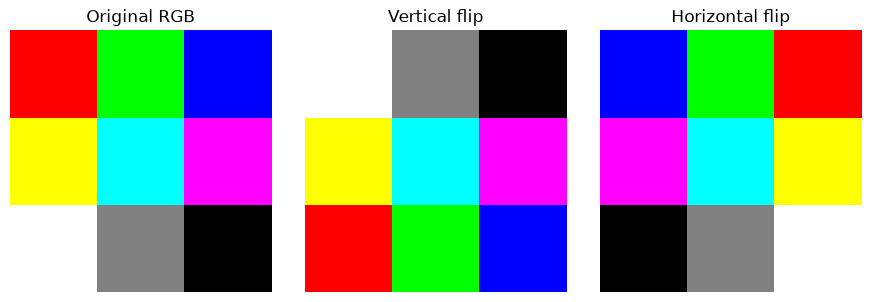

In [20]:
#3.4 Flipping Arrays (np.flip)
vertical_flip = np.flip(rgb_image, axis=0)
horizontal_flip = np.flip(rgb_image, axis=1)

print("Original red channel:")
print(rgb_image[:, :, 0])
print("Vertical flip (axis=0):")
print(vertical_flip[:, :, 0])
print("Horizontal flip (axis=1):")
print(horizontal_flip[:, :, 0])
print("Flipped shape:", horizontal_flip.shape)
#--------------------------------------------------------
# Opsional untuk menampilkan gambar pada contoh Section 3:
# %pip install matplotlib
import matplotlib
print("Matplotlib version:", matplotlib.__version__)
#---------------------------------------------------------
try:
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(9, 3))
    for axis, picture, label in zip(
        axes,
        [rgb_image, vertical_flip, horizontal_flip],
        ["Original RGB", "Vertical flip", "Horizontal flip"]
    ):
        axis.imshow(picture)
        axis.set_title(label)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib belum terpasang. instal matplotlib.")

In [21]:
#4. Transposing Arrays
#4.1 Array Transposition
data_matrix = np.array([[1, 2, 3],
                        [4, 5, 6]])

print("Original:")
print(data_matrix)
print("Shape:", data_matrix.shape)
print("Transposed:")
print(data_matrix.T)
print("Transposed shape:", np.transpose(data_matrix).shape)
print("1D transpose shape:", np.array([1, 2, 3]).T.shape)

Original:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Transposed:
[[1 4]
 [2 5]
 [3 6]]
Transposed shape: (3, 2)
1D transpose shape: (3,)


In [22]:
#4.2 Transposing by Axis
data_3d = np.arange(24).reshape(2, 3, 4)
reordered = np.transpose(data_3d, axes=(1, 0, 2))

print("=== ORIGINAL ARRAY ===")
print("Shape:", data_3d.shape)
print(data_3d)

print("\nLayer 0:")
print(data_3d[0])

print("\nLayer 1:")
print(data_3d[1])

print("\n=== TRANSPOSED ARRAY ===")
print("Shape:", reordered.shape)
print(reordered)

print("\nLayer 0:")
print(reordered[0])

print("\nLayer 1:")
print(reordered[1])

print("\nLayer 2:")
print(reordered[2])

print("\n=== ELEMENT COMPARISON ===")
print("Original [1, 2, 3]:", data_3d[1, 2, 3])
print("Transposed [2, 1, 3]:", reordered[2, 1, 3])

print("\n=== SWAPAXES ===")
print(np.swapaxes(data_3d, 0, 1))

=== ORIGINAL ARRAY ===
Shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Layer 1:
[[12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

=== TRANSPOSED ARRAY ===
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [12 13 14 15]]

Layer 1:
[[ 4  5  6  7]
 [16 17 18 19]]

Layer 2:
[[ 8  9 10 11]
 [20 21 22 23]]

=== ELEMENT COMPARISON ===
Original [1, 2, 3]: 23
Transposed [2, 1, 3]: 23

=== SWAPAXES ===
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]


In [23]:
#5. Stacking and Splitting Arrays
#5.1 Splitting Arrays (np.split)
monthly_values = np.array([10, 12, 15, 18, 20, 22])
first_half, second_half = np.split(monthly_values, 2)

print("First half:", first_half)
print("Second half:", second_half)

measurement_table = np.arange(1, 13).reshape(3, 4)
left_part, right_part = np.split(measurement_table, 2, axis=1)

print("Original table:")
print(measurement_table)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print("Unequal split example:", [part.tolist() for part in np.array_split(np.arange(7), 3)])

First half: [10 12 15]
Second half: [18 20 22]
Original table:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]
Unequal split example: [[0, 1, 2], [3, 4], [5, 6]]


In [24]:
#5.2 Stacking Arrays (np.stack)
day_one = np.array([12, 15, 18])
day_two = np.array([10, 17, 20])

stacked_rows = np.stack((day_one, day_two), axis=0)
stacked_columns = np.stack((day_one, day_two), axis=1)

print("Original vector shape:", day_one.shape)
print("Stacked by rows:")
print(stacked_rows)
print("Shape:", stacked_rows.shape)
print("Stacked by columns:")
print(stacked_columns)
print("Shape:", stacked_columns.shape)

Original vector shape: (3,)
Stacked by rows:
[[12 15 18]
 [10 17 20]]
Shape: (2, 3)
Stacked by columns:
[[12 10]
 [15 17]
 [18 20]]
Shape: (3, 2)


In [25]:
#5.3 Reshaping Split Arrays
first_block, second_block = np.split(measurement_table, 2, axis=1)
first_vector = first_block.reshape(-1)
second_vector = second_block.reshape(-1)
reshaped_and_stacked = np.stack((first_vector, second_vector), axis=0)

print("Shape of each split block:", first_block.shape)
print("Shape after reshape:", first_vector.shape)
print("Reshaped and stacked:")
print(reshaped_and_stacked)
print("New shape:", reshaped_and_stacked.shape)

Shape of each split block: (3, 2)
Shape after reshape: (6,)
Reshaped and stacked:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
New shape: (2, 6)


In [26]:
#6. Independent Student Exercises
import numpy as np

scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

col_bonus = np.array([5, 3, 2])
score_col_bonus = scores + col_bonus

row_bonus = np.array([1, 4, 2]).reshape(-1, 1)
score_row_bonus = scores + row_bonus

col_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - col_means

print("=== Exercise 1 ===")
print(f"Col bonus shape: {col_bonus.shape} | Score + col bonus shape: {score_col_bonus.shape}")
print("Hasil bonus per kolom:\n", score_col_bonus)

print(f"\nRow bonus shape: {row_bonus.shape} | Score + row bonus shape: {score_row_bonus.shape}")
print("Hasil bonus per baris:\n", score_row_bonus)

print(f"\nCol means shape: {col_means.shape} | Centered scores shape: {centered_scores.shape}")
print("Hasil centering:\n", centered_scores)


temperatures = np.array([[29, 31, 30], 
                         [28, 32, 33], 
                         [27, 30, 31]])

np.save("week11_temperatures.npy", temperatures)
loaded_temperatures = np.load("week11_temperatures.npy", allow_pickle=False)

print("\n=== Exercise 2 ===")
print("Loaded Shape :", loaded_temperatures.shape)
print("Loaded Ndim  :", loaded_temperatures.ndim)
print("Loaded Dtype :", loaded_temperatures.dtype)
print("Apakah array asli dan hasil pemuatan identik?:", np.array_equal(temperatures, loaded_temperatures))


image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)

red_ch = image[:, :, 0]
green_ch = image[:, :, 1]
blue_ch = image[:, :, 2]

no_blue_img = image.copy()
no_blue_img[:, :, 2] = 0

bright_img = np.clip(image.astype(np.int16) + 30, 0, 255).astype(np.uint8)

flip_vert = np.flip(image, axis=0)
flip_horiz = np.flip(image, axis=1)

print("\n=== Exercise 3 ===")
print("Bentuk gambar (Height, Width, Channels):", image.shape)
print("Red Channel:\n", red_ch)
print("Green Channel:\n", green_ch)
print("Blue Channel:\n", blue_ch)
print("Piksel [0, 0] Asli               :", image[0, 0])
print("Piksel [0, 0] Tanpa Kanal Blue   :", no_blue_img[0, 0])
print("Piksel [0, 0] Lebih Cerah        :", bright_img[0, 0])
print("Piksel [0, 0] Vertical Flip      :", flip_vert[0, 0])
print("Piksel [0, 0] Horizontal Flip    :", flip_horiz[0, 0])


arr = np.arange(24).reshape(2, 3, 4)

arr_transposed = np.transpose(arr, axes=(1, 0, 2))
arr_swapped = np.swapaxes(arr, 0, 1)

image_hwc = np.zeros((4, 5, 3))
image_chw = np.transpose(image_hwc, (2, 0, 1))
restored_hwc = np.transpose(image_chw, (1, 2, 0))

print("\n=== Exercise 4 ===")
print("Shape awal arr:", arr.shape)
print("Shape setelah np.transpose(1, 0, 2):", arr_transposed.shape)
print("Shape setelah np.swapaxes(0, 1)    :", arr_swapped.shape)
print("Apakah transposisi dan swapaxes identik?:", np.array_equal(arr_transposed, arr_swapped))
print("Shape HWC asli:", image_hwc.shape)
print("Shape CHW     :", image_chw.shape)
print("Shape HWC lagi:", restored_hwc.shape)


data = np.arange(1, 13).reshape(3, 4)

part1, part2 = np.split(data, 2, axis=1)
vec1 = part1.reshape(-1)
vec2 = part2.reshape(-1)
stacked_data = np.stack((vec1, vec2), axis=0)
unequal_splits = np.array_split(np.arange(10), 3)

print("\n=== Exercise 5 ===")
print(f"Shape Part 1: {part1.shape} | Shape Part 2: {part2.shape}")
print(f"Shape Vektor 1D: {vec1.shape}")
print("Hasil stack (axis=0):\n", stacked_data)
print("Shape hasil stack:", stacked_data.shape)
print("Hasil array_split 10 elemen menjadi 3 bagian:")
for i, p in enumerate(unequal_splits):
    print(f" Bagian {i+1} (panjang {len(p)}): {p.tolist()}")


rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])

loc_means = np.mean(rainfall, axis=0, keepdims=True)
centered_rainfall = rainfall - loc_means

np.save("week11_centered_rainfall.npy", centered_rainfall)
loaded_centered = np.load("week11_centered_rainfall.npy", allow_pickle=False)

transposed_rainfall = loaded_centered.T
split1, split2 = np.split(transposed_rainfall, 2, axis=1)
reconstructed_rainfall = np.concatenate((split1, split2), axis=1)

print("\n=== Exercise 6 ===")
print("Shape asal (hari, lokasi)       :", rainfall.shape)
print("Shape transposisi (lokasi, hari):", transposed_rainfall.shape)
print("Shape Split 1                   :", split1.shape)
print("Shape Split 2                   :", split2.shape)
print("Shape Reconstructed             :", reconstructed_rainfall.shape)
print("Apakah data pasca-rekonstruksi identik dengan data ter-transposisi?:", 
      np.array_equal(transposed_rainfall, reconstructed_rainfall))

=== Exercise 1 ===
Col bonus shape: (3,) | Score + col bonus shape: (3, 3)
Hasil bonus per kolom:
 [[75 83 92]
 [80 88 97]
 [65 73 82]]

Row bonus shape: (3, 1) | Score + row bonus shape: (3, 3)
Hasil bonus per baris:
 [[71 81 91]
 [79 89 99]
 [62 72 82]]

Col means shape: (1, 3) | Centered scores shape: (3, 3)
Hasil centering:
 [[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]

=== Exercise 2 ===
Loaded Shape : (3, 3)
Loaded Ndim  : 2
Loaded Dtype : int64
Apakah array asli dan hasil pemuatan identik?: True

=== Exercise 3 ===
Bentuk gambar (Height, Width, Channels): (2, 2, 3)
Red Channel:
 [[255   0]
 [  0 255]]
Green Channel:
 [[  0 255]
 [  0 255]]
Blue Channel:
 [[  0   0]
 [255 255]]
Piksel [0, 0] Asli               : [255   0   0]
Piksel [0, 0] Tanpa Kanal Blue   : [255   0   0]
Piksel [0, 0] Lebih Cerah        : [255  30  30]
Piksel [0, 0] Vertical Flip      : [  0   0 255]
Piksel [0, 0] Horizontal Flip    : [  